# Proyecto integrador: perfiles de edificaciones con K-Means
**Henry David Muñoz Molina — USTA Tunja — Minería de Datos**

Objetivo: explorar y segmentar la base de elaboración propia, vinculando el análisis con el ODS 11. Alcance: avance académico, sin certificación de seguridad estructural. Ejecute desde la carpeta del proyecto.

## 1. Configuración y carga

Configuración y carga reproducible.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
ROOT = Path.cwd()
if not (ROOT/'data/08_dataset_simplificado.csv').exists():
    raise FileNotFoundError('Ejecute desde la carpeta del proyecto; consulte README.md.')
for folder in ['results','figures']: (ROOT/folder).mkdir(exist_ok=True)
raw = pd.read_csv(ROOT/'data/08_dataset_simplificado.csv')
df = raw.copy()
SEED=42
plt.rcParams.update({'font.size':9,'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False})
def save(name):
    plt.tight_layout(); plt.savefig(ROOT/'figures'/f'{name}.png',dpi=180,bbox_inches='tight'); plt.close()
print('Dimensiones originales:', raw.shape)


Dimensiones originales: (15010, 9)


## 2. Calidad y limpieza verificable

Auditoría de esquema, nulos, dominios, IDs y atípicos. Los extremos se conservan provisionalmente; no se certifica su validez externa.

In [2]:
expected=['id_edificacion','ciudad','tipo_edificio','numero_pisos','sistema_estructural','amenaza_sismica','cumple_norma_sismorresistente','antiguedad','potencial_estructura_metalica']
assert df.columns.tolist()==expected
for c in df.select_dtypes(include=['object','string']).columns:
    df[c]=df[c].str.strip().replace(r'^\s*$',np.nan,regex=True)
assert df.notna().all().all(), 'Nulos detectados: revisar la fuente, no imputar silenciosamente.'
assert df.id_edificacion.str.fullmatch(r'ED-\d{6}').all()
assert not df.id_edificacion.duplicated().any(), 'Resolver IDs repetidos con la fuente.'
assert not df.duplicated().any()
df['numero_pisos']=pd.to_numeric(df.numero_pisos,errors='raise')
assert ((df.numero_pisos>0)&(df.numero_pisos%1==0)).all()
domains={
'ciudad':['Bogotá','Medellín','Cali','Barranquilla','Bucaramanga','Cartagena'],
'tipo_edificio':['Apartamentos','Uso mixto','Oficinas','Comercial','Institucional','Hotel'],
'sistema_estructural':['Concreto reforzado','Acero estructural','Sistema mixto','Muros de carga'],
'amenaza_sismica':['Baja','Intermedia','Alta'],
'antiguedad':['Reciente (0-10 años)','Moderado (11-25 años)','Antiguo (26-40 años)','Muy antiguo (>40 años)'],
'potencial_estructura_metalica':['baja','media','alta','muy_alta'],
'cumple_norma_sismorresistente':['No','Sí']}
for c,vals in domains.items(): assert df[c].isin(vals).all(), f'Categorías inesperadas: {c}'
df['potencial_estructura_metalica']=df.potencial_estructura_metalica.map({'baja':'Baja','media':'Media','alta':'Alta','muy_alta':'Muy alta'})
df['cumple_norma_sismorresistente']=df.cumple_norma_sismorresistente.map({'No':False,'Sí':True})
q1,q3=df.numero_pisos.quantile([.25,.75]); low,high=q1-1.5*(q3-q1),q3+1.5*(q3-q1)
out=(df.numero_pisos<low)|(df.numero_pisos>high)
df.loc[out].to_csv(ROOT/'results/atipicos_para_revision.csv',index=False)
# Los 267 casos se conservan provisionalmente; plausibilidad no equivale a validación externa.
df.to_csv(ROOT/'data/08_dataset_limpio.csv',index=False)
audit={'rows':len(df),'columns':len(df.columns),'nulls':int(df.isna().sum().sum()),'duplicates':int(df.duplicated().sum()),'outliers_iqr':int(out.sum()),'iqr_limits':[float(low),float(high)],'sha256_input':hashlib.sha256((ROOT/'data/08_dataset_simplificado.csv').read_bytes()).hexdigest()}
print(json.dumps(audit,indent=2))


{
  "rows": 15010,
  "columns": 9,
  "nulls": 0,
  "duplicates": 0,
  "outliers_iqr": 267,
  "iqr_limits": [
    -14.0,
    50.0
  ],
  "sha256_input": "38611ce28742c936dca9202abafde46265b579171e7e2651f0528310a47050ea"
}


## 3. EDA: distribuciones, cruces y asociaciones

Distribuciones, porcentajes dentro de grupos, cruces y asociaciones descriptivas.

count    15010.000000
mean        19.564424
std         11.126251
min          5.000000
25%         10.000000
50%         18.000000
75%         26.000000
max         55.000000
                 n  mean_floors  compliance
ciudad                                     
Barranquilla  2101      19.4003      0.2461
Bogotá        4003      19.5826      0.0007
Bucaramanga   1900      19.8089      0.0000
Cali          2503      19.7783      0.0000
Cartagena     1800      19.2189      0.2267
Medellín      2703      19.5253      0.0000
Asociaciones más fuertes: ciudad                         amenaza_sismica                  0.999900
                               cumple_norma_sismorresistente    0.431427
amenaza_sismica                cumple_norma_sismorresistente    0.431171
sistema_estructural            potencial_estructura_metalica    0.227106
potencial_estructura_metalica  cumple_norma_sismorresistente    0.220008
tipo_edificio                  potencial_estructura_metalica    0.184251
sistema_

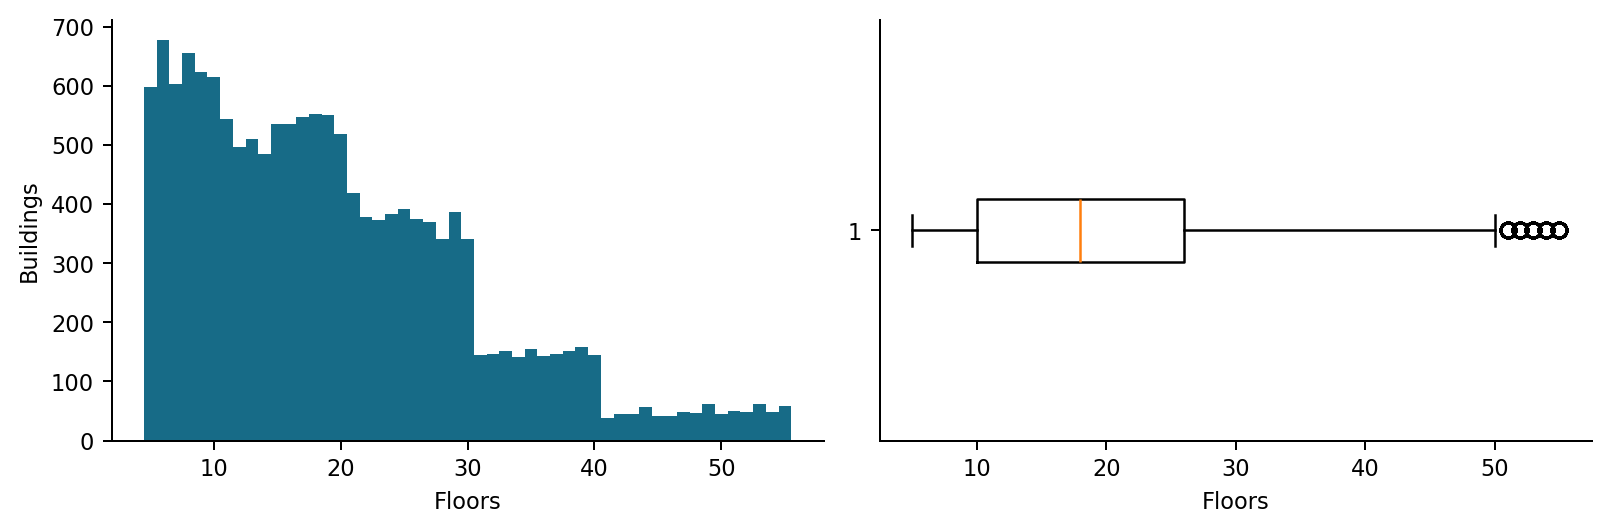

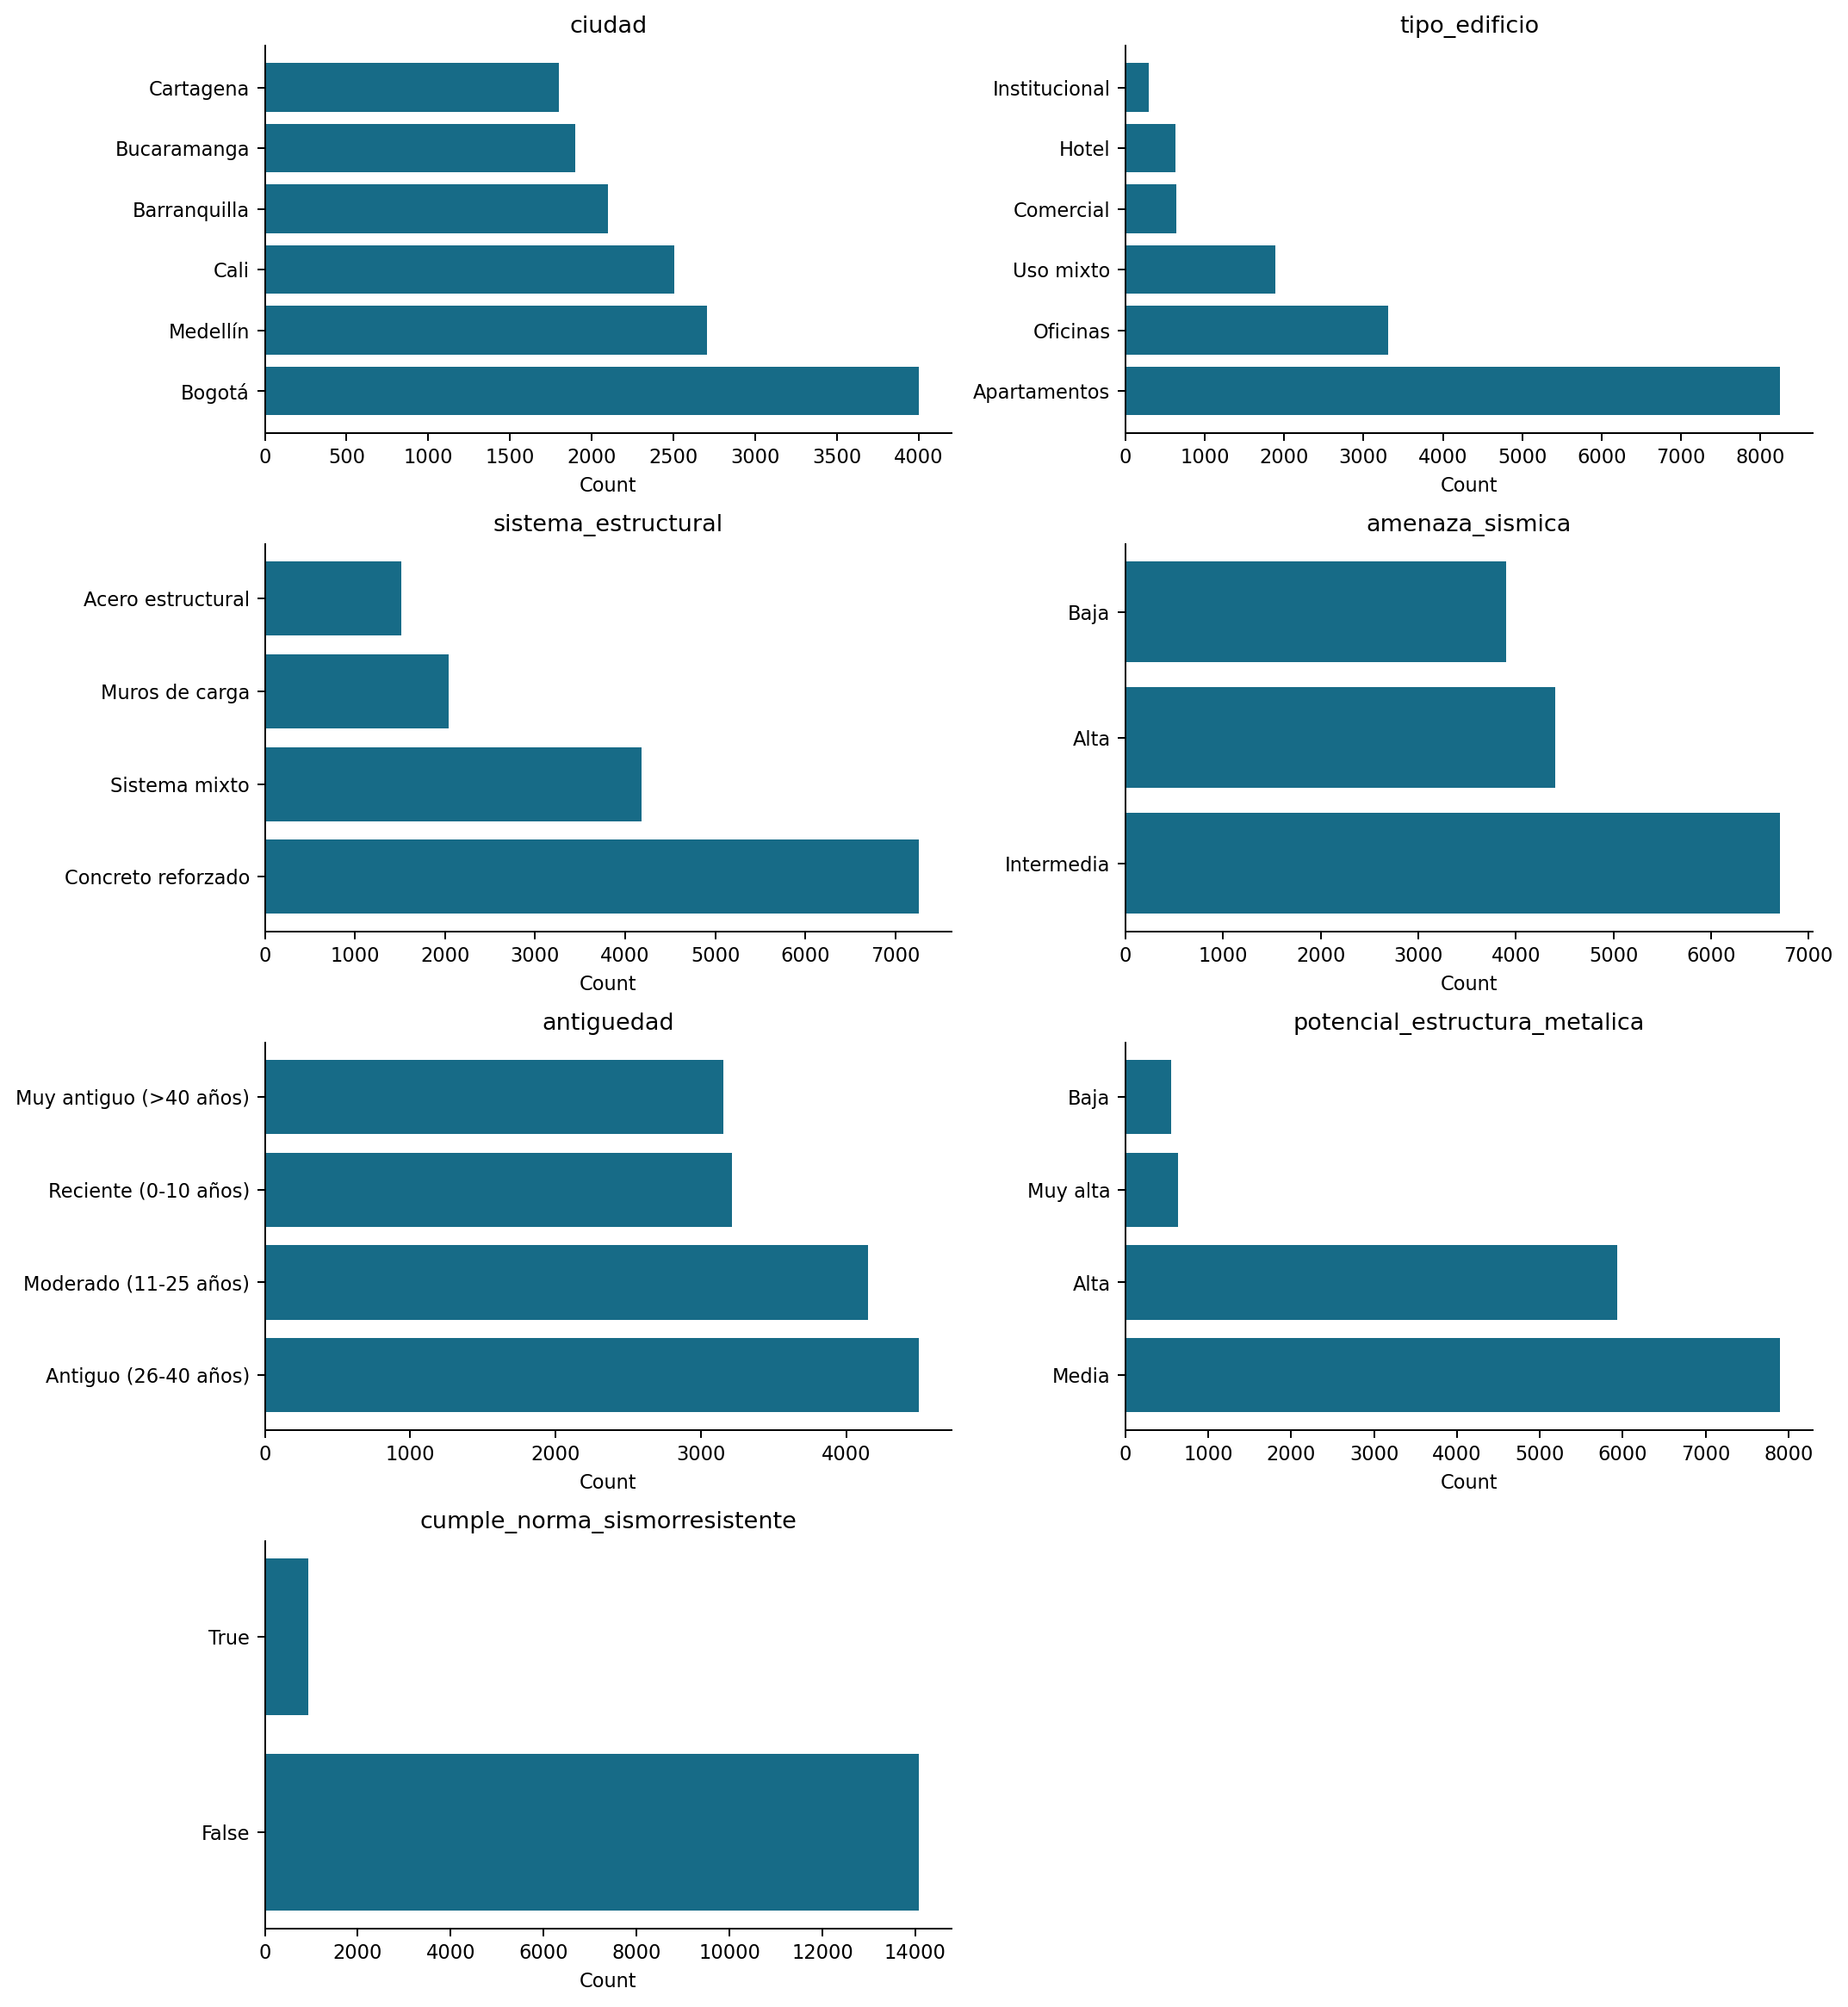

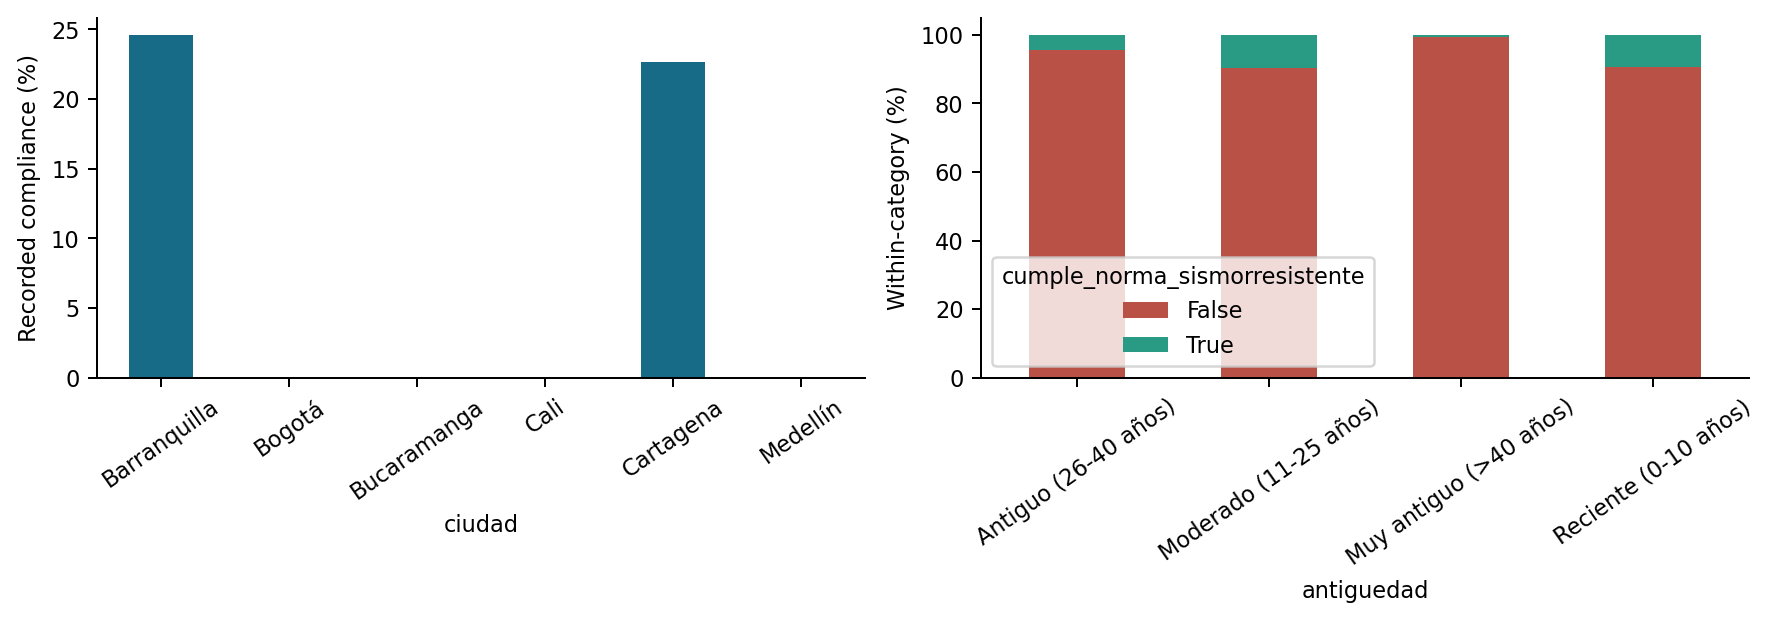

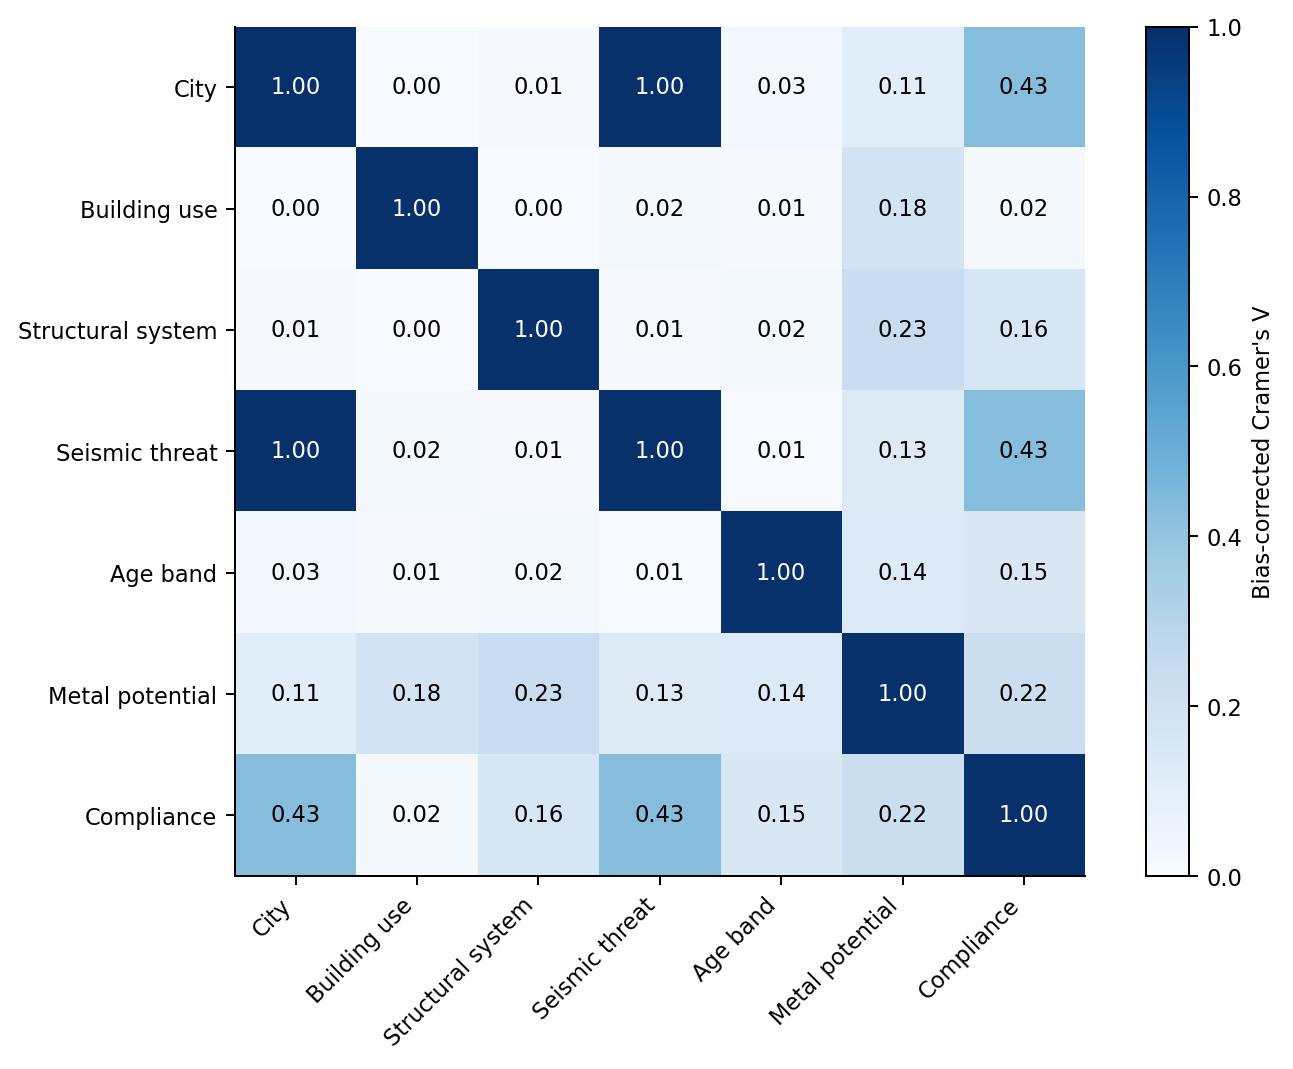

In [3]:
print(df.numero_pisos.describe().to_string())
df.numero_pisos.describe().to_csv(ROOT/'results/estadisticas_pisos.csv')
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].hist(df.numero_pisos,bins=np.arange(4.5,56.5),color='#176B87');ax[0].set(xlabel='Floors',ylabel='Buildings')
ax[1].boxplot(df.numero_pisos,vert=False);ax[1].set_xlabel('Floors');save('01_floors')
cats=list(domains)
fig,axs=plt.subplots(4,2,figsize=(12,13))
for ax,c in zip(axs.flat,cats):
    counts=df[c].value_counts();ax.barh(counts.index.astype(str),counts.values,color='#176B87');ax.set_title(c);ax.set_xlabel('Count')
axs.flat[-1].axis('off');save('02_categories')
for c in cats:
    df[c].value_counts(dropna=False).rename_axis(c).to_csv(ROOT/'results'/f'frecuencia_{c}.csv')
city=df.groupby('ciudad').agg(n=('id_edificacion','size'),mean_floors=('numero_pisos','mean'),compliance=('cumple_norma_sismorresistente','mean'))
city.to_csv(ROOT/'results/resumen_ciudades.csv');print(city.round(4).to_string())
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
city.compliance.mul(100).plot.bar(ax=axs[0],color='#176B87');axs[0].set_ylabel('Recorded compliance (%)')
pd.crosstab(df.antiguedad,df.cumple_norma_sismorresistente,normalize='index').mul(100).plot.bar(stacked=True,ax=axs[1],color=['#BA5146','#299B85']);axs[1].set_ylabel('Within-category (%)')
for ax in axs: ax.tick_params(axis='x',labelrotation=35)
save('03_compliance')
# Cramér V corregido por sesgo: relación categórica, no causalidad.
def cramers(a,b):
    t=pd.crosstab(a,b); n=t.values.sum(); r,k=t.shape
    chi=chi2_contingency(t,correction=False)[0]
    phi=max(0,chi/n-(k-1)*(r-1)/(n-1)); rc=r-(r-1)**2/(n-1);kc=k-(k-1)**2/(n-1)
    return np.sqrt(phi/min(kc-1,rc-1))
v=pd.DataFrame([[cramers(df[a],df[b]) for b in cats] for a in cats],index=cats,columns=cats)
v.to_csv(ROOT/'results/cramers_v.csv')
fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(v,vmin=0,vmax=1,cmap='Blues')
short=['City','Building use','Structural system','Seismic threat','Age band','Metal potential','Compliance']
ax.set_xticks(range(7),short,rotation=45,ha='right');ax.set_yticks(range(7),short)
for i in range(7):
 for j in range(7): ax.text(j,i,f'{v.iloc[i,j]:.2f}',ha='center',va='center',color='white' if v.iloc[i,j]>.55 else 'black')
fig.colorbar(im,ax=ax,label="Bias-corrected Cramer's V");save('04_associations')
for c in ['ciudad','antiguedad','sistema_estructural','amenaza_sismica']:
    pd.crosstab(df[c],df.cumple_norma_sismorresistente).to_csv(ROOT/'results'/f'cruce_{c}_cumplimiento.csv')
print('Asociaciones más fuertes:',v.where(np.triu(np.ones(v.shape),1).astype(bool)).stack().sort_values(ascending=False).head(8).to_string())


## 4. Representación para K-Means

Representación de datos mixtos: pisos estandarizados, one-hot ponderado y cumplimiento binario. Variables sin interpretación métrica se excluyen.

In [4]:
# Se excluyen ID (sin significado métrico), ciudad (perfil posterior) y potencial
# (regla de construcción desconocida; se evita circularidad).
# Edad es un rango, no años exactos. One-hot evita inventar distancias entre rangos.
features=['tipo_edificio','sistema_estructural','antiguedad','amenaza_sismica']
def encode(frame, clip=False):
    floors=frame[['numero_pisos']].copy()
    if clip: floors=floors.clip(lower=low,upper=high)
    scaler=StandardScaler(); num=scaler.fit_transform(floors)
    enc=OneHotEncoder(sparse_output=False,handle_unknown='error')
    cat=enc.fit_transform(frame[features])/np.sqrt(2)
    # Una diferencia categórica aporta 1 a la distancia euclídea al cuadrado.
    binary=frame[['cumple_norma_sismorresistente']].astype(float).to_numpy()
    return np.column_stack([num,cat,binary]),scaler,enc
X,scaler,enc=encode(df)
print('Matriz para clustering:',X.shape)


Matriz para clustering: (15010, 19)


## 5. Elección de k y evaluación interna

Selección entre 2 y 8 grupos; silueta sobre la misma muestra de 2500 filas y métricas complementarias.

 k    inertia  silhouette_sample_2500  davies_bouldin  calinski_harabasz  min_cluster
 2 25814.6043                  0.2499          1.5091          5917.0948         5117
 3 23142.1612                  0.1567          1.9365          4166.4785         2023
 4 21688.9285                  0.1212          2.2022          3298.7183         1819
 5 20664.1783                  0.1165          2.3820          2782.5818         1846
 6 19478.4623                  0.1369          2.1955          2544.0840         1675
 7 18937.7155                  0.1270          2.2146          2251.8603          672
 8 18171.7198                  0.1352          2.0776          2101.7348          651
k seleccionado por máxima silueta en la misma muestra: 2


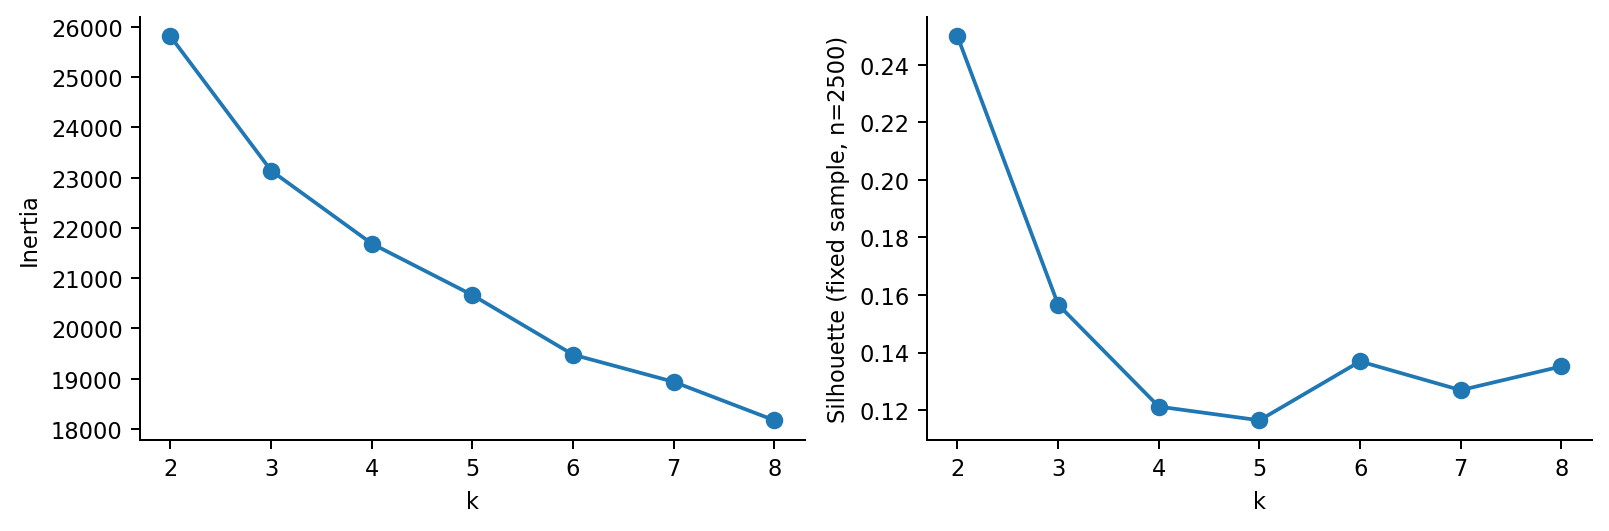

In [5]:
rows=[]; models={}
for k in range(2,9):
    model=KMeans(n_clusters=k,init='k-means++',n_init=20,random_state=SEED,max_iter=300).fit(X)
    models[k]=model;labels=model.labels_
    rows.append({'k':k,'inertia':model.inertia_,'silhouette_sample_2500':silhouette_score(X,labels,sample_size=2500,random_state=SEED),'davies_bouldin':davies_bouldin_score(X,labels),'calinski_harabasz':calinski_harabasz_score(X,labels),'min_cluster':int(np.bincount(labels).min())})
metrics=pd.DataFrame(rows);metrics.to_csv(ROOT/'results/evaluacion_k.csv',index=False)
best_k=int(metrics.sort_values(['silhouette_sample_2500','k'],ascending=[False,True]).iloc[0].k)
model=models[best_k];labels=model.labels_
print(metrics.round(4).to_string(index=False)); print('k seleccionado por máxima silueta en la misma muestra:',best_k)
fig,axs=plt.subplots(1,2,figsize=(9,3))
axs[0].plot(metrics.k,metrics.inertia,'o-');axs[0].set(xlabel='k',ylabel='Inertia')
axs[1].plot(metrics.k,metrics.silhouette_sample_2500,'o-');axs[1].set(xlabel='k',ylabel='Silhouette (fixed sample, n=2500)');save('05_selection')


## 6. Estabilidad y sensibilidad

Estabilidad entre semillas y sensibilidad al tratamiento de pisos. ARI no es precisión ni seguridad.

In [6]:
stability=[]
for seed in [7,21,84]:
    other=KMeans(n_clusters=best_k,n_init=20,random_state=seed).fit_predict(X)
    stability.append({'seed':seed,'ARI':adjusted_rand_score(labels,other)})
Xclip,_,_=encode(df,clip=True)
clip_labels=KMeans(n_clusters=best_k,n_init=20,random_state=SEED).fit_predict(Xclip)
clip_ari=adjusted_rand_score(labels,clip_labels)
# Sensibilidad al peso de pisos: mitad del peso de distancia al cuadrado.
Xhalf=X.copy();Xhalf[:,0]*=np.sqrt(.5)
half_labels=KMeans(n_clusters=best_k,n_init=20,random_state=SEED).fit_predict(Xhalf)
half_ari=adjusted_rand_score(labels,half_labels)
pd.DataFrame(stability).to_csv(ROOT/'results/estabilidad.csv',index=False)
print('Estabilidad:',stability);print('ARI recorte IQR:',clip_ari,'ARI peso pisos 0.5:',half_ari)


Estabilidad: [{'seed': 7, 'ARI': 1.0}, {'seed': 21, 'ARI': 1.0}, {'seed': 84, 'ARI': 1.0}]
ARI recorte IQR: 1.0 ARI peso pisos 0.5: 0.9220755442966404


## 7. Perfiles e interpretación descriptiva

Perfiles en variables originales. PCA solo para visualizar. No se asignan etiquetas de riesgo estructural.

            n  mean_floors  median_floors  compliance_pct  share_pct tipo_edificio_mode sistema_estructural_mode       antiguedad_mode amenaza_sismica_mode ciudad_mode potencial_estructura_metalica_mode
cluster                                                                                                                                                                                                   
0        9893       13.003           13.0            6.51     65.909       Apartamentos       Concreto reforzado  Antiguo (26-40 años)           Intermedia      Bogotá                              Media
1        5117       32.251           29.0            5.55     34.091       Apartamentos       Concreto reforzado  Antiguo (26-40 años)           Intermedia      Bogotá                               Alta
Validación final: registros conservados y asignación completa.


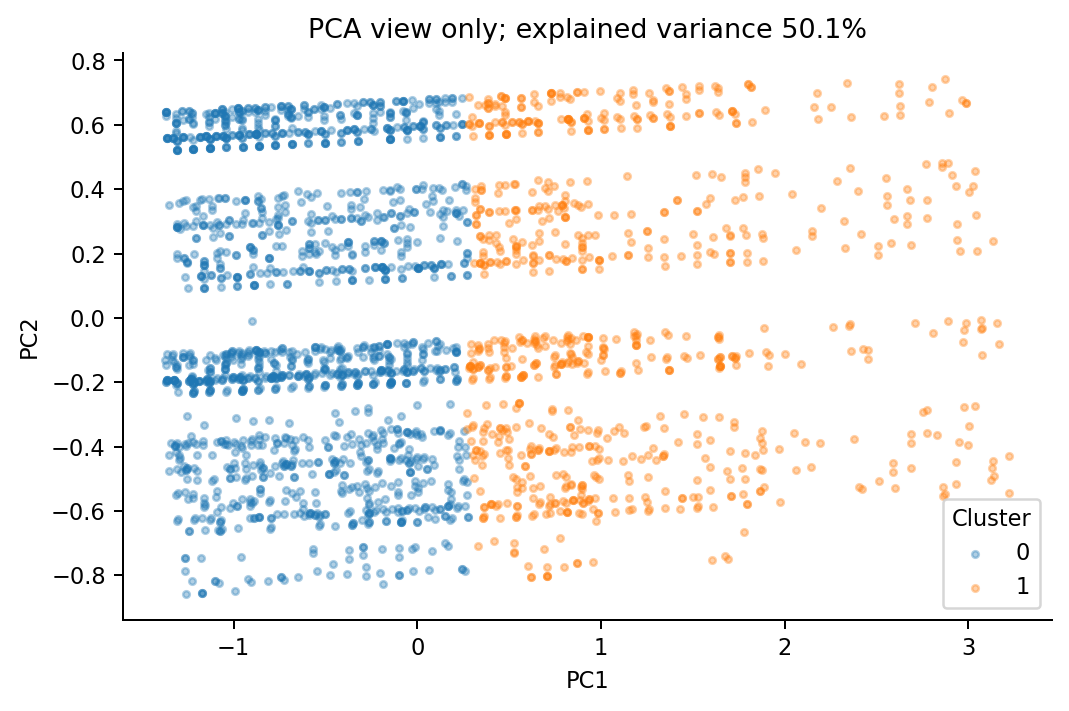

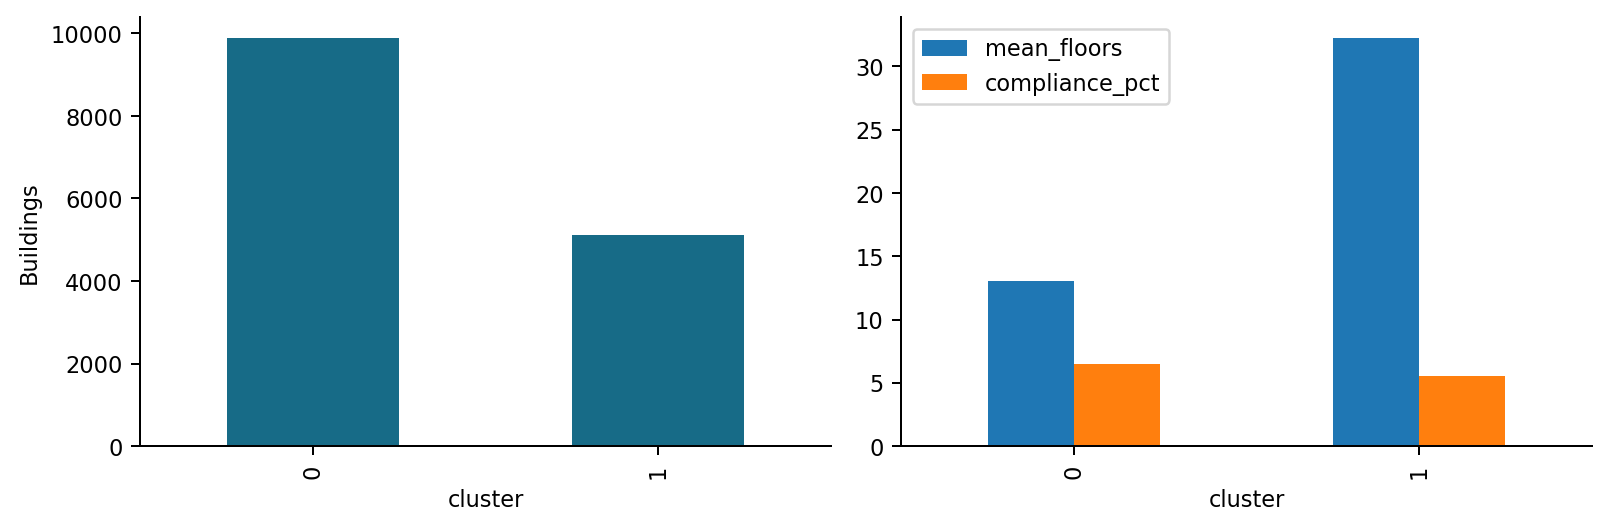

In [7]:
result=df.assign(cluster=labels)
result.to_csv(ROOT/'data/edificaciones_segmentadas.csv',index=False)
profile=result.groupby('cluster').agg(n=('id_edificacion','size'),mean_floors=('numero_pisos','mean'),median_floors=('numero_pisos','median'),compliance_pct=('cumple_norma_sismorresistente',lambda x:100*x.mean()))
profile['share_pct']=100*profile.n/len(result)
for c in features+['ciudad','potencial_estructura_metalica']:
    profile[c+'_mode']=result.groupby('cluster')[c].agg(lambda x:x.mode().iloc[0])
    pd.crosstab(result.cluster,result[c],normalize='index').to_csv(ROOT/'results'/f'perfil_{c}.csv')
profile.to_csv(ROOT/'results/perfiles.csv');print(profile.round(3).to_string())
pca=PCA(n_components=2,random_state=SEED);coords=pca.fit_transform(X)
fig,ax=plt.subplots(figsize=(6,4));rng=np.random.default_rng(SEED);ix=rng.choice(len(df),2500,replace=False)
for k in range(best_k):
    s=ix[labels[ix]==k];ax.scatter(coords[s,0],coords[s,1],s=7,alpha=.35,label=str(k))
ax.set(xlabel='PC1',ylabel='PC2',title=f'PCA view only; explained variance {pca.explained_variance_ratio_.sum():.1%}');ax.legend(title='Cluster');save('06_pca')
fig,axs=plt.subplots(1,2,figsize=(9,3));profile.n.plot.bar(ax=axs[0],color='#176B87');axs[0].set_ylabel('Buildings');profile[['mean_floors','compliance_pct']].plot.bar(ax=axs[1]);save('07_profiles')
summary={**audit,'best_k':best_k,'silhouette':float(metrics.set_index('k').loc[best_k,'silhouette_sample_2500']),'stability':stability,'clipped_ari':clip_ari,'half_floor_weight_ari':half_ari,'pca_variance':float(pca.explained_variance_ratio_.sum()),'compliance_pct':100*df.cumple_norma_sismorresistente.mean()}
(ROOT/'results/summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
import sklearn,scipy
(ROOT/'results/environment.json').write_text(json.dumps({'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__},indent=2))
print('Validación final: registros conservados y asignación completa.')
assert len(result)==len(raw) and result.cluster.notna().all() and profile.n.sum()==len(raw)


## 8. Sensibilidad a una variable de procedencia no verificada

Se elimina cumplimiento del ajuste para comprobar dependencia de una variable no verificada, conservando k para hacer una comparación controlada.

In [8]:
# Eliminar cumplimiento del ajuste evalúa dependencia de esa variable, sin certificarla.
X_without_compliance = X[:, :-1]
no_compliance_labels = KMeans(n_clusters=best_k, n_init=20, random_state=SEED).fit_predict(X_without_compliance)
no_compliance_result = {
    'k_fixed_to_baseline': best_k,
    'ari_vs_baseline': float(adjusted_rand_score(labels, no_compliance_labels)),
    'silhouette_without_compliance': float(silhouette_score(X_without_compliance, no_compliance_labels, sample_size=2500, random_state=SEED)),
    'note': 'Sensitivity at fixed k; not external validation of compliance or a new k search.'
}
(ROOT/'results/sensitivity_no_compliance.json').write_text(json.dumps(no_compliance_result,indent=2))
print(json.dumps(no_compliance_result,indent=2))


{
  "k_fixed_to_baseline": 2,
  "ari_vs_baseline": 1.0,
  "silhouette_without_compliance": 0.25446301296040885,
  "note": "Sensitivity at fixed k; not external validation of compliance or a new k search."
}


## 9. Consumo de fuente externa oficial y contraste independiente

Consumo real de la API de Catastro Bogotá. Se reutiliza una respuesta archivada con hash; --refresh realiza una nueva consulta. Se contrastan distribuciones por pisos sin unir edificios ni afirmar representatividad. Los registros catastrales son elementos de una capa, no necesariamente edificios independientes.

{
  "external_total": 2422631,
  "external_valid_positive_integer_floor_records": 2406292,
  "external_missing_or_invalid_floor_records": 16339,
  "external_mean_floors_valid": 2.107773703274582,
  "constructed_bogota_n": 4003,
  "constructed_bogota_mean_floors": 19.58256307769173,
  "source_sha256": "eeebc67f17f6f05907542b134286f5a791ba090090b61e75922dc15babce13e9",
  "retrieved_at_utc": "2026-11-14T14:35:01.029809+00:00"
}
       catastro_count  constructed_count  catastro_pct  constructed_pct
1–4           2336920                  0        97.117            0.000
5–10            63533               1027         2.640           25.656
11–20            5280               1395         0.219           34.849
21–50             556               1511         0.023           37.747
51+                 3                 70         0.000            1.749


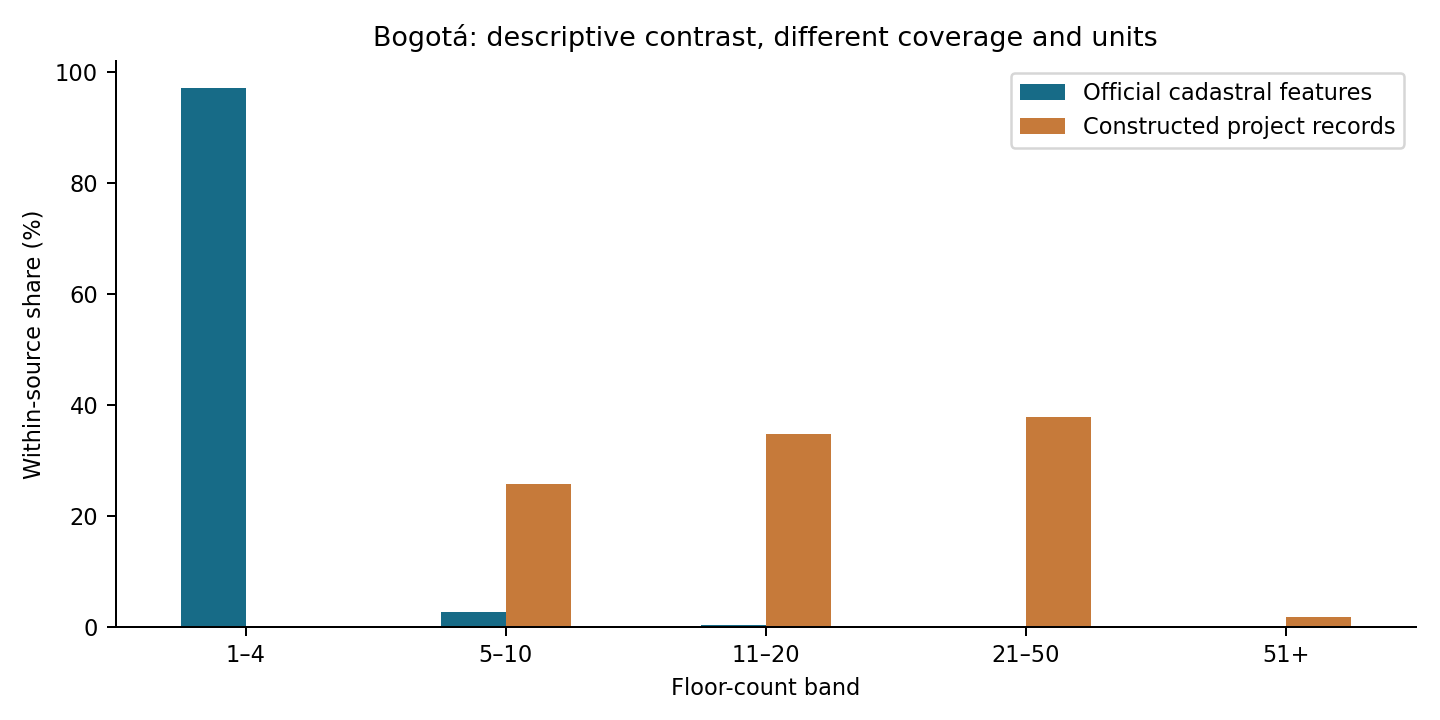

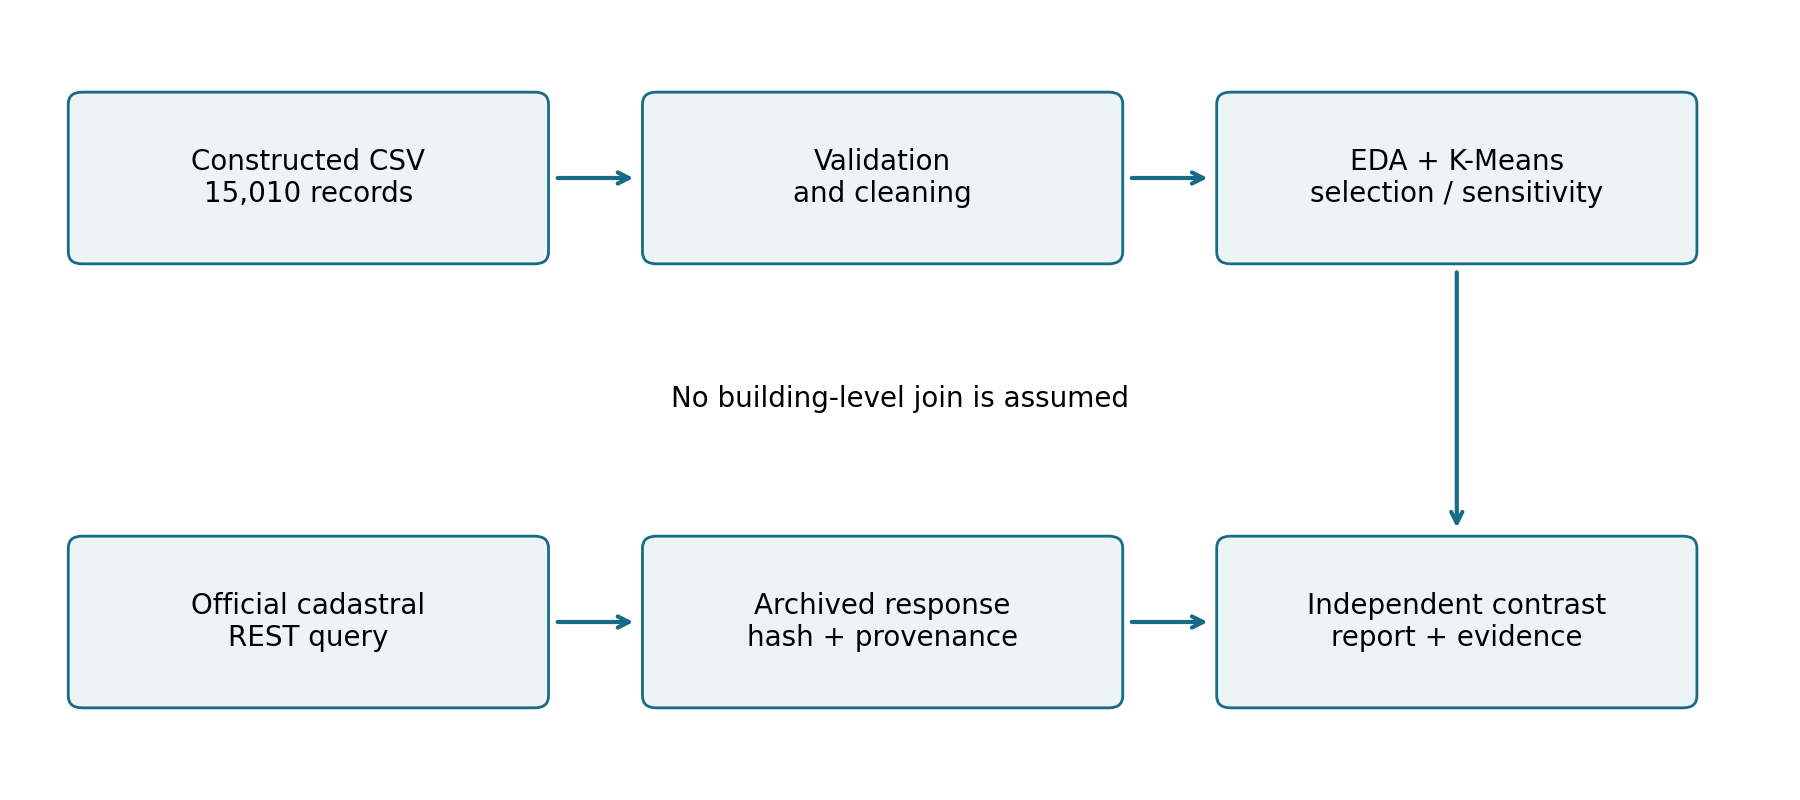

In [9]:
# El snapshot tiene procedencia, fecha, parámetros y hash; permite réplica sin conexión.
# Para actualizarlo explícitamente: python external_data.py --refresh
from external_data import run as run_external
external_result = run_external(refresh=False)


## Conclusiones y alcance

El conjunto propio produce dos perfiles principalmente diferenciados por altura. La consulta oficial externa está implementada y documentada. El contraste con Catastro no valida los registros propios: evidencia una cobertura y unidad diferentes. El análisis no certifica seguridad sísmica. Las reglas históricas de construcción de la base no están verificadas.

Referencias oficiales, limitaciones y correspondencia de campos: FUENTES_OFICIALES_RECOMENDADAS.md. Autor único: **Henry David Muñoz Molina**.